In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import cv2
from ultralytics import YOLO
import warnings
warnings.filterwarnings('ignore')
# 关闭此 Notebook 的 Weigths & Biases (wandb) 报告功能
os.environ['WANDB_DISABLED'] = 'true'

In [2]:
def load_image_and_labels(image_path, label_path):
    """
    加载图片并在其上绘制 YOLO 格式的目标检测边界框

    参数：
    image_path (str): 图片文件的路径
    label_path (str): 对应标签文件的路径

    返回：
    Image: 绘制了边界框的 PIL 图片对象
    """
    # 打开图片文件
    image = Image.open(image_path)
    # 创建一个绘图对象用于在图片上绘制边界框
    draw = ImageDraw.Draw(image)

    # 读取标签文件中的每一行
    with open(label_path, 'r') as f:
        lines = f.readlines()

    # 遍历每一行标签信息
    for line in lines:
        # 去除行末换行符并分割成列表
        parts = line.strip().split()
        # 获取类别 ID （虽然在这个例子中没有使用）
        class_id = int(parts[0])
        # 获取归一化的边界框中心坐标和宽高
        x_center, y_center, width, height = map(float, parts[1:5])

        # 获取图片的宽度和高度
        img_width, img_height = image.size

        # 将归一化的边界框坐标转换为像素值
        box_left = (x_center - width / 2) * img_width
        box_top = (y_center - height / 2) * img_height
        box_right = (x_center + width / 2) * img_width
        box_bottom = (y_center + height / 2) * img_height

        # 在图片上绘制矩形边界框
        draw.rectangle([box_left, box_top, box_right, box_bottom], outline = 'red', width = 3)

        return image

In [3]:
def visualize_images(image_folder, label_folder, num_images = 9):
    """
    随机选取指定数量的图片，并在其上绘制边界框后进行可视化

    参数：
    image_folder (str): 存放图片文件的文件夹路径
    label_folder (str): 存放对应标签文件的文件夹路径
    num_images (int): 要可视化的图片数量，默认为 9
    """
    # 获取所有图片文件名
    image_files = [f for f in os.listdir(image_folder) if f.endswith('.jpg')]
    # 随机选择指定数量的图片文件
    selected_images = random.sample(image_files, num_images)

    # 创建子图布局，这里设置为 3 行 3 列
    fig, axes = plt.subplots(nrows = 3, ncols = 3, figsize = (15, 15))
    # 将 axes 展平为一维数组以便逐个处理
    axes = axes.flatten()

    # 遍历选中的每一张图
    for ax, img_file in zip(axes, selected_images):
        # 构建图片文件的完整路径
        img_path = os.path.join(image_folder, img_file)
        # 构建对应标签文件的完整路径
        label_path = os.path.join(label_folder, img_file.replace('.jpg', '.txt'))

        # 加载图片并在其上绘制边界框
        image_with_boxes = load_image_and_labels(img_path, label_path)
        # 显示图片
        ax.imshow(image_with_boxes)
        # 关闭坐标轴显示
        ax.axis('off')

    # 自动调整子图参数，使其填充整个图片区域
    plt.tight_layout()
    # 显示所有图片
    plt.show()
    

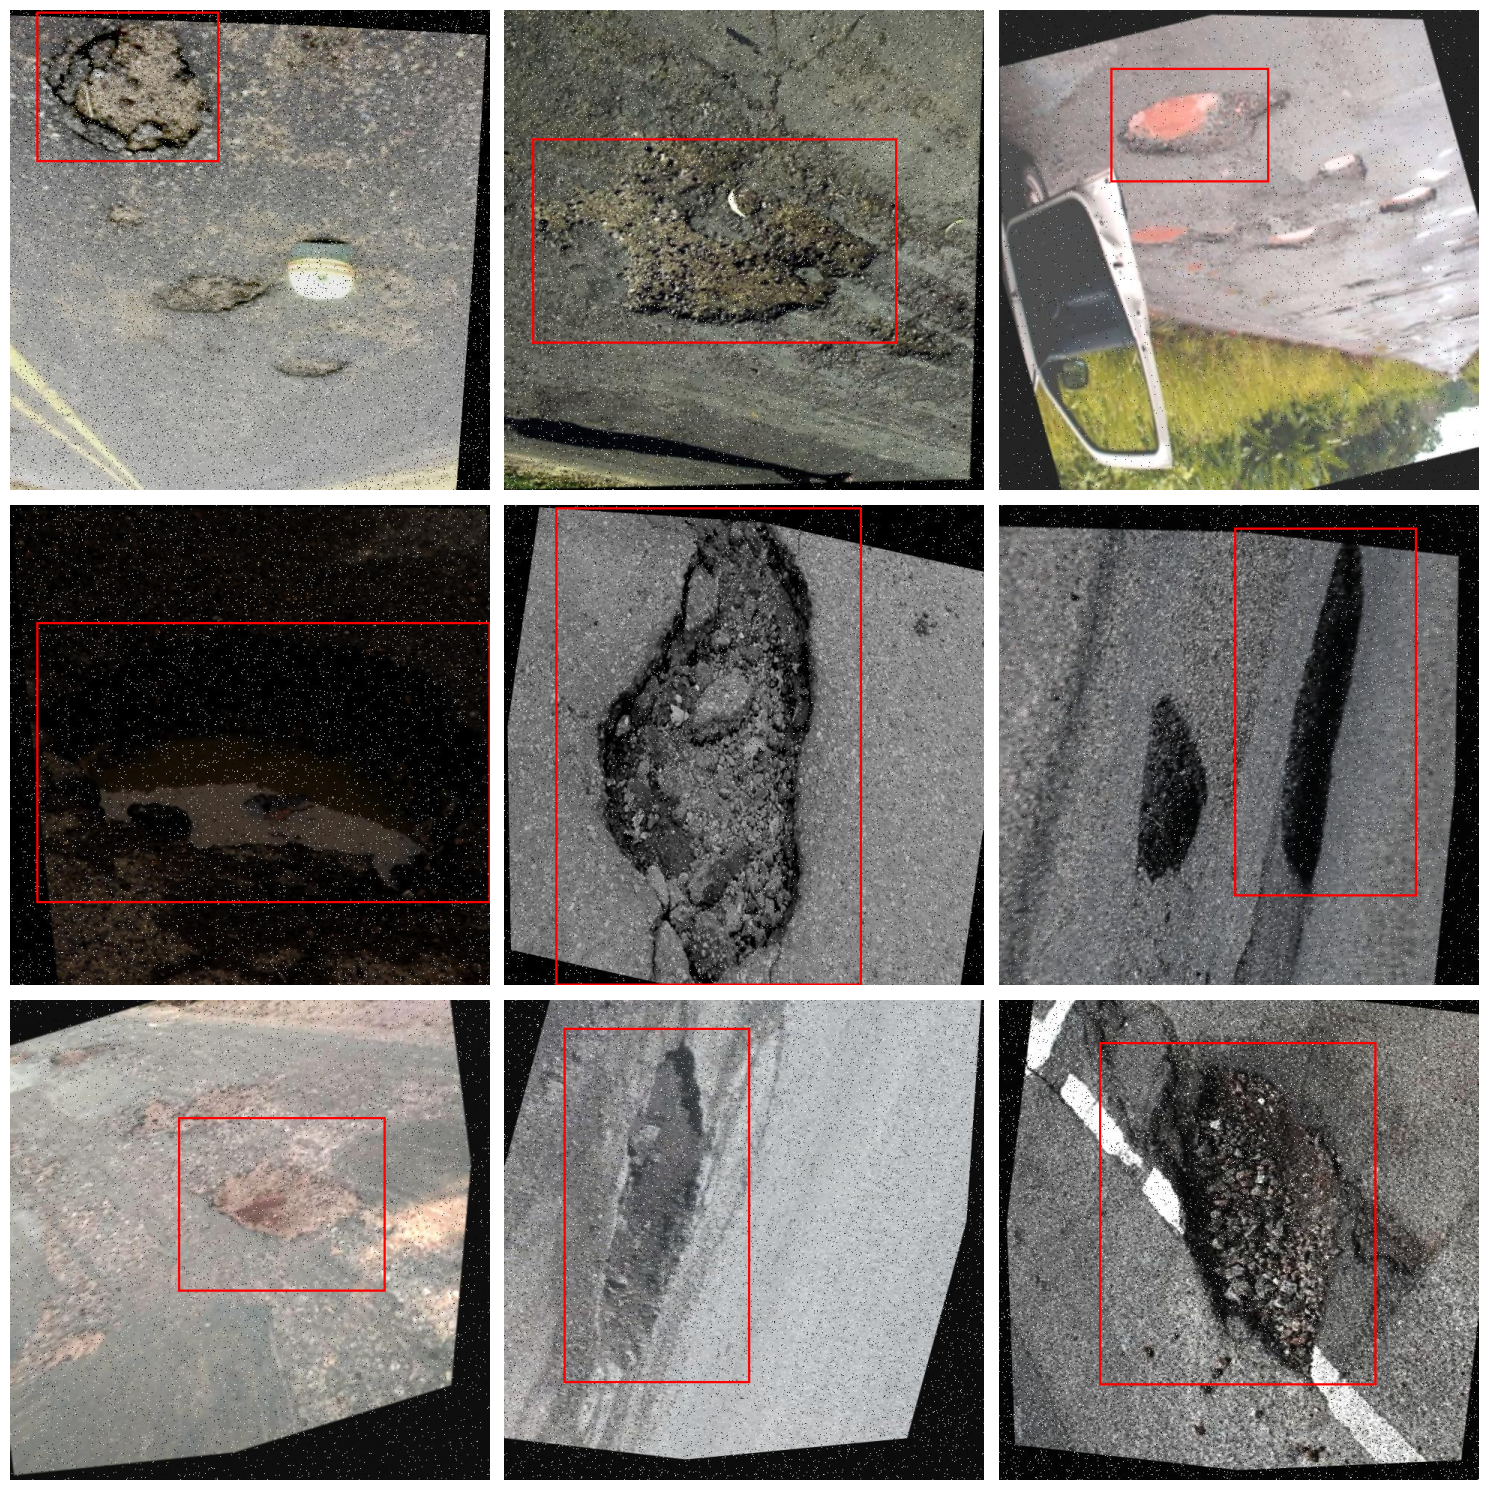

In [4]:
# 定义图片和标签文件夹的路径
image_folder = 'archive/train/images'
label_folder = 'archive/train/labels'
# 调用函数进行可视化
visualize_images(image_folder, label_folder)

## 随机抽取一张图片查看图片大小

In [7]:
import cv2
# 定义选择的图片样本数量
num_samples = 1
# 获取图片文件夹中的所有图片文件名
image_files = os.listdir(image_folder)
# 从图片文件列表中随机选择指定数量的图片文件
selected_image = random.sample(image_files, num_samples)
# 构建图片文件的完整路径
img_path = os.path.join(image_folder, selected_image[0])
# 读取图片文件
img = cv2.imread(img_path)
# 打印图片的大小
print(" 图片大小： ", img.shape)

 图片大小：  (640, 640, 3)


In [8]:
import os

def calculate_label_file_sizes_and_zero_size_files(directory):
    """
    计算指定目录中所有 .txt 文件的大小，并统计文件大小为 0 的数量

    参数：
    directory (str): 存放标签文件的文件夹路径
    
    返回：
    tuple: 包含总文件大小（字节）和文件大小为 0 的数量
    """
    total_size = 0
    zero_size_count = 0

    # 获取所有标签文件名
    label_files = [f for f in os.listdir(directory) if f.endswith('.txt')]

    for label_file in label_files:
        # 构建标签文件的完整路径
        file_path = os.path.join(directory, label_file)

        # 获取文件大小
        file_size = os.path.getsize(file_path)
        total_size += file_size

        # 统计文件大小为 0 的数量
        if file_size == 0:
            zero_size_count += 1

    return total_size, zero_size_count

# 定义训练集和验证集标签文件夹的路径
train_label_folder = 'archive/train/labels'
valid_label_folder = 'archive/valid/labels'

# 计算训练集标签文件的大小和统计文件大小为 0 的数量
train_total_size, train_zero_size_count = calculate_label_file_sizes_and_zero_size_files(train_label_folder)

# 计算验证集标签文件的大小和统计文件大小为 0 的数量
valid_total_size, valid_zero_size_count = calculate_label_file_sizes_and_zero_size_files(valid_label_folder)

# 打印结果
print(f"Train Labels Directory:")
print(f"Total Size: {train_total_size} bytes")
print(f"Number of Files with Size 0: {train_zero_size_count}")

print(f"\nValid Labels Directory:")
print(f"Total Size: {valid_total_size} bytes")
print(f"Number of Files with Size 0: {valid_zero_size_count}")

Train Labels Directory:
Total Size: 323701 bytes
Number of Files with Size 0: 0

Valid Labels Directory:
Total Size: 1040 bytes
Number of Files with Size 0: 0
